# Combined VisionSpeak

This notebook provides one webcam interface for the custom eight-word lip reader and the 18-label YOLO gesture detector. The two models run in isolated Python environments so MediaPipe and Ultralytics never load competing OpenCV wheels in the same process.

## Controls

- **Space** — in lip mode, start a two-second countdown and record one three-second word.
- **M** — release the webcam and switch to the other prediction mode.
- **Q** — release the webcam and finish the session.

Only live webcam frames are processed. This notebook does not record audio or save video. Select the **VisionSpeak Lip** kernel created from `requirements.txt`; the YOLO worker is launched automatically from `.venv-yolo`.

## 1. Load the project launcher

Run this notebook from anywhere inside the repository. The following cell locates the project root and imports the standard-library launcher.

In [ ]:
from pathlib import Path
import os
import sys

from IPython.display import Markdown, display


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'requirements.txt').is_file() and (candidate / 'inference').is_dir():
            return candidate
    raise FileNotFoundError('Could not find the VisionSpeak project root.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from inference.launcher import (
    CombinedConfig,
    ConfigurationError,
    run_combined_session,
    validate_combined_config,
)

print(f'Project root: {PROJECT_ROOT}')
print(f'Notebook kernel: {sys.executable}')

## 2. Install environments (first run)

The two workers must stay in separate environments because MediaPipe and Ultralytics depend on different OpenCV wheels. This cell is safe to run every time: it probes imports first and only installs what is missing.

- **Lip environment** — if this kernel cannot import `cv2`, `mediapipe`, or `torch`, `requirements.txt` is pip-installed into the running interpreter. Restart the kernel afterwards so the new packages load.
- **YOLO environment** — `.venv-yolo` is created when missing and `requirements-yolo.txt` is installed into it only when its imports are unavailable.

Set `FORCE_REINSTALL = True` to recreate or repopulate either environment from scratch.

In [ ]:
from inference.environment_setup import (
    setup_lip_environment,
    setup_worker_environment,
)

INSTALL_LIP = True
INSTALL_YOLO = True
FORCE_REINSTALL = False

if INSTALL_LIP:
    lip_installed = setup_lip_environment(
        PROJECT_ROOT / 'requirements.txt',
        force=FORCE_REINSTALL,
    )
    if lip_installed:
        print('Lip environment: packages installed. Restart the kernel, then rerun this notebook from the top.')
    else:
        print('Lip environment: ready.')
else:
    print('Lip environment: skipped (INSTALL_LIP = False).')

if INSTALL_YOLO:
    yolo_python, yolo_installed = setup_worker_environment(
        PROJECT_ROOT / '.venv-yolo',
        PROJECT_ROOT / 'requirements-yolo.txt',
        force=FORCE_REINSTALL,
    )
    status = 'installed' if yolo_installed else 'ready'
    print(f'YOLO worker: {status} at {yolo_python}')
else:
    print('YOLO worker: skipped (INSTALL_YOLO = False).')

## 3. Configure the session

Leave the interpreter values as `None` for automatic `.venv` and `.venv-yolo` discovery. Set an absolute path only when your environments use different names.

In [ ]:
INITIAL_MODE = 'lip'  # 'lip' or 'gesture'
CAMERA_INDEX = 0
LIP_PYTHON = None
GESTURE_PYTHON = None
LIP_DEVICE = 'auto'  # auto, cpu, cuda, or mps
GESTURE_DEVICE = None  # None lets Ultralytics choose

CONFIG = CombinedConfig(
    project_root=PROJECT_ROOT,
    initial_mode=INITIAL_MODE,
    camera_index=CAMERA_INDEX,
    lip_python=LIP_PYTHON,
    gesture_python=GESTURE_PYTHON,
    lip_checkpoint='checkpoints/valente_custom_words_lipnet_ctc_0.852_acc.pt',
    gesture_checkpoint='checkpoints/sx_transformer_TwoHandAndBody_best.pt',
    countdown_seconds=2.0,
    capture_seconds=3.0,
    min_frames=30,
    min_detection_rate=0.75,
    max_frames=90,
    gesture_confidence=0.5,
    lip_device=LIP_DEVICE,
    gesture_device=GESTURE_DEVICE,
)
CONFIG

## 4. Validate environments and checkpoints

This check runs imports in each isolated interpreter without opening the webcam. Any missing dependency or path is reported before the session starts.

In [ ]:
try:
    RESOLVED_CONFIG = validate_combined_config(CONFIG, check_imports=True)
except ConfigurationError as error:
    display(Markdown(f'### ❌ Configuration error\n\n```text\n{error}\n```'))
    raise
else:
    display(Markdown('### ✅ Both worker environments are ready'))
    print(f'Lip Python:     {RESOLVED_CONFIG.lip_python}')
    print(f'Gesture Python: {RESOLVED_CONFIG.gesture_python}')
    print(f'Lip checkpoint: {RESOLVED_CONFIG.lip_checkpoint.name}')
    print(f'Gesture backend: {RESOLVED_CONFIG.gesture_backend}')
    print(f'Gesture checkpoint: {RESOLVED_CONFIG.gesture_checkpoint.name}')

## 5. Start the combined webcam session

An OpenCV window will open. Keep that window focused when using Space, M, or Q. Mode switches briefly close the window while the current worker releases the camera and the other model loads.

In [ ]:
SESSION_SUMMARY = run_combined_session(CONFIG)
print('Combined session finished.')

## 6. Session summary

In [ ]:
if 'SESSION_SUMMARY' not in globals():
    raise RuntimeError('Run the combined webcam session cell first.')

status = '✅ Completed' if SESSION_SUMMARY.completed else '❌ Stopped with an error'
display(Markdown(f'### {status}'))
print(f'Initial mode: {SESSION_SUMMARY.initial_mode}')
print(f'Mode switches: {SESSION_SUMMARY.switch_count}')
for number, event in enumerate(SESSION_SUMMARY.events, start=1):
    print(
        f'{number}. {event.mode}: {event.action} '
        f'(exit {event.return_code}, {event.elapsed_seconds:.1f}s)'
    )
if SESSION_SUMMARY.error:
    display(Markdown(f'**Error:** `{SESSION_SUMMARY.error}`'))

## 7. Offline epoch-sweep evaluation

Optional, and no webcam is involved. Choose one checkpoint directory per architecture and a folder of recorded clips, then run the cell below: it scores all twelve checkpoints — 4 architectures x 3 epoch budgets — on the same mouth frames and prints the accuracy table with a confusion matrix for each.

This drives `evaluate_epoch_sweep.py`, the same engine the command line uses, so a notebook run and `reports/retrain/epoch_sweep_mp4.md` cannot disagree.


## LBY: So the checkpoints have already been saved as 50 epoch, 100 epoch and 200 epoch formats.
## Over here, what is more useful to the user is to indicate the TEST DATA.
## All you need to do, is to point to the correct MP4 directory under the CLIPS_DIR variable.

Clips: 160 from /home/lbyubuntu/Documents/Github Projects/VisionSpeak/data/custom_words/raw/speaker_test_samples
  frames 10/160 (0s, cache=True)
  frames 20/160 (0s, cache=True)
  frames 30/160 (0s, cache=True)
  frames 40/160 (0s, cache=True)
  frames 50/160 (0s, cache=True)
  frames 60/160 (0s, cache=True)
  frames 70/160 (0s, cache=True)
  frames 80/160 (0s, cache=True)
  frames 90/160 (0s, cache=True)
  frames 100/160 (0s, cache=True)
  frames 110/160 (0s, cache=True)


I0000 00:00:1791993601.065203  144502 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1791993601.066422  169059 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.1.3), renderer: AMD Radeon RX 7800 XT (radeonsi, navi32, ACO, DRM 3.64, 7.0.0-34-generic)
W0000 00:00:1791993601.066745  144502 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1791993601.070116  169074 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791993601.082341  169066 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  frames 120/160 (0s, cache=True)
  frames 130/160 (0s, cache=True)
  frames 140/160 (0s, cache=True)
  frames 150/160 (0s, cache=True)
  frames 160/160 (0s, cache=True)
  [1/3] CTC + BiGRU        @  50 epochs   16.25%  (26/160, cuda)
  [1/3] CTC + Transformer  @  50 epochs   23.75%  (38/160, cuda)
  [1/3] Word + BiGRU       @  50 epochs   34.38%  (55/160, cuda)
  [1/3] Word + Transformer @  50 epochs   40.62%  (65/160, cuda)
  [2/3] CTC + BiGRU        @ 100 epochs   31.87%  (51/160, cuda)
  [2/3] CTC + Transformer  @ 100 epochs   24.38%  (39/160, cuda)
  [2/3] Word + BiGRU       @ 100 epochs   37.50%  (60/160, cuda)
  [2/3] Word + Transformer @ 100 epochs   35.00%  (56/160, cuda)
  [3/3] CTC + BiGRU        @ 200 epochs   49.38%  (79/160, cuda)
  [3/3] CTC + Transformer  @ 200 epochs   40.62%  (65/160, cuda)
  [3/3] Word + BiGRU       @ 200 epochs   34.38%  (55/160, cuda)
  [3/3] Word + Transformer @ 200 epochs   49.38%  (79/160, cuda)


### Overall test accuracy

| epoch | CTC + BiGRU | CTC + Transformer | Word + BiGRU | Word + Transformer |
| --- | --- | --- | --- | --- |
| 50 | 16.25% | 23.75% | 34.38% | 40.62% |
| 100 | 31.87% | 24.38% | 37.50% | 35.00% |
| 200 | 49.38% | 40.62% | 34.38% | 49.38% |

### Clips correct

| epoch | CTC + BiGRU | CTC + Transformer | Word + BiGRU | Word + Transformer |
| --- | --- | --- | --- | --- |
| 50 | 26/160 | 38/160 | 55/160 | 65/160 |
| 100 | 51/160 | 39/160 | 60/160 | 56/160 |
| 200 | 79/160 | 65/160 | 55/160 | 79/160 |

Written: epoch_sweep_notebook.md, epoch_sweep_notebook.csv, epoch_sweep_notebook_predictions.csv, epoch_sweep_notebook_confusion.png


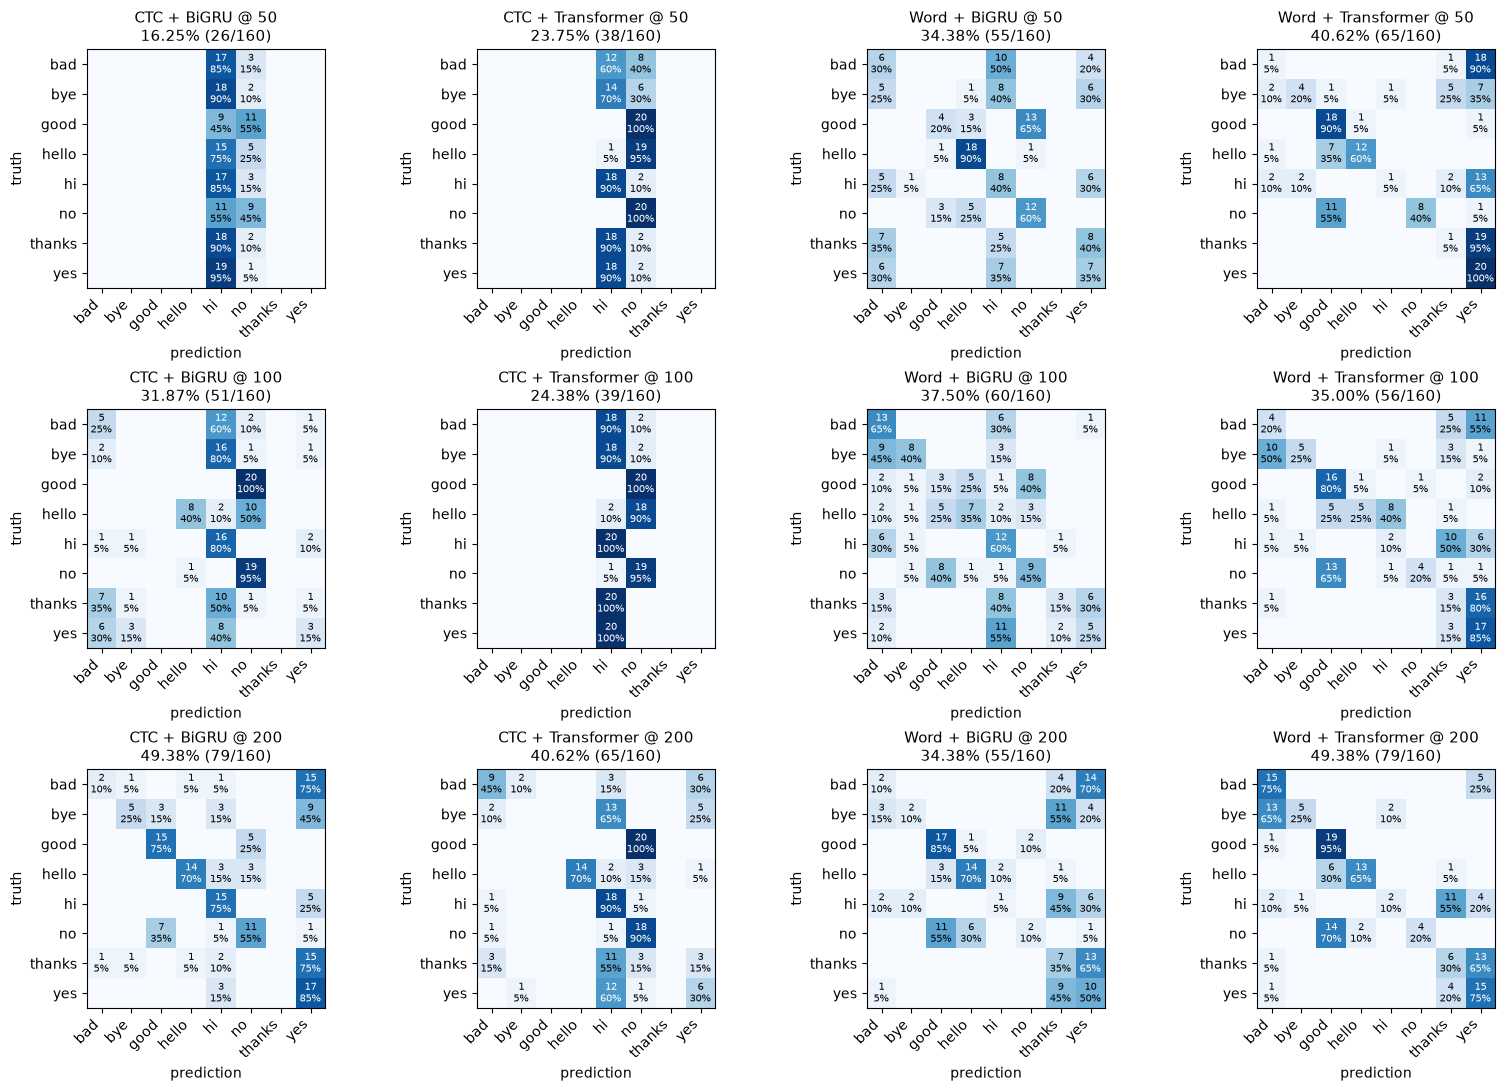

In [ ]:
# ---- configuration: edit this block ----
# One checkpoint directory per architecture. Each must hold
# <arch>_ep<epoch>.pt for every budget in EPOCH_BUDGETS, which is what
# scripts/retrain_lip_models.sh writes (run once per budget, with TAG=ep<N>).
CHECKPOINT_DIRS = {
    'ctc_bigru':                  'checkpoints/retrain',
    'ctc_transformer':            'checkpoints/retrain',
    'word_bigru':                 'checkpoints/retrain',
    'word_transformer_attention': 'checkpoints/retrain',
}

EPOCH_BUDGETS = (50, 100, 200)  # table rows; every column needs one per budget

# A folder of recordings shaped <CLIPS_DIR>/<word>/*.mp4. Its name is taken as
# the speaker id, so the guard below can refuse a checkpoint that trained on it.
#CLIPS_DIR = 'data/custom_words/raw/speaker_test_samples' #LBY recording
#CLIPS_DIR = 'data/custom_words/raw/LY_001' #Lawrence's wife recording
CLIPS_DIR = 'data/custom_words/raw/speaker_test_samples1' #valente's recording

DEVICE = 'auto'                 # auto, cpu, cuda (ROCm reports as cuda), or mps
ALLOW_SPEAKER_MISMATCH = True #False  # True scores checkpoints that did NOT hold the speaker out
LIMIT = None                    # e.g. 8 for a smoke run; takes the first N clips, word by word
SAVE_ARTIFACTS = True           # write the table, CSV and figure under reports/retrain/
STEM = 'epoch_sweep_notebook'   # kept distinct from the CLI's epoch_sweep_mp4.*

# ---- run ----
import matplotlib.pyplot as plt

import evaluate_epoch_sweep as sweep
from IPython.display import Markdown, display

# compare_lip_models forces the Agg backend when it is imported, which would
# render nothing here. Switch back to inline figures after that import.
%matplotlib inline

clips_dir = (PROJECT_ROOT / CLIPS_DIR).resolve()
rows = sweep.rows_from_clip_directory(clips_dir)
if LIMIT:
    rows = rows.head(LIMIT)
print(f'Clips: {len(rows)} from {clips_dir}')

grid = sweep.build_grid_from_sets(CHECKPOINT_DIRS, EPOCH_BUDGETS)
try:
    warnings = sweep.validate_grid(
        grid, EPOCH_BUDGETS, sweep.ARCHITECTURES,
        expected_speaker=clips_dir.name,
        allow_speaker_mismatch=ALLOW_SPEAKER_MISMATCH,
    )
except sweep.SweepError as error:
    display(Markdown(f'### ❌ Checkpoint grid rejected\n\n```text\n{error}\n```'))
    raise
for message in warnings:
    print(f'warning: {message}')

summaries, per_clip = sweep.run_sweep(
    grid, rows, EPOCH_BUDGETS, sweep.ARCHITECTURES,
    data_dir=PROJECT_ROOT / 'data/custom_words',
    cache_dir=PROJECT_ROOT / '.cache/lip_mp4_frames',
    device=DEVICE,
    max_frames=90, min_frames=30, min_detection_rate=0.75,
    progress=lambda line: print(line, flush=True),
)

accuracy_grid = sweep.render_grid(
    lambda epoch, key: sweep.format_percent(summaries[(epoch, key)]['accuracy']),
    EPOCH_BUDGETS,
)
count_grid = sweep.render_grid(
    lambda epoch, key: (
        f"{summaries[(epoch, key)]['correct']}/{summaries[(epoch, key)]['predicted']}"
    ),
    EPOCH_BUDGETS,
)
display(Markdown(
    '### Overall test accuracy\n\n' + sweep.format_markdown(accuracy_grid) +
    '\n\n### Clips correct\n\n' + sweep.format_markdown(count_grid)
))

figure = sweep.render_confusion_grid(summaries, EPOCH_BUDGETS, sweep.ARCHITECTURES)
if SAVE_ARTIFACTS:
    markdown_path, csv_path, per_clip_path = sweep.write_artifacts(
        summaries,
        PROJECT_ROOT / 'reports/retrain',
        STEM,
        epochs=EPOCH_BUDGETS,
        per_clip=per_clip,
        context={
            'Speaker held out': clips_dir.name,
            'Clips': len(rows),
            'Source': str(clips_dir),
            'Checkpoints': ', '.join(sorted(set(CHECKPOINT_DIRS.values()))),
        },
    )
    figure_path = PROJECT_ROOT / 'reports/retrain' / f'{STEM}_confusion.png'
    figure.savefig(figure_path, dpi=110, bbox_inches='tight')
    print(
        f'Written: {markdown_path.name}, {csv_path.name}, '
        f'{per_clip_path.name}, {figure_path.name}'
    )

display(figure)
plt.close(figure)  # already rendered above; stops the inline backend repeating it
